# Parte 1 Características de calidad de los datos

In [ ]:
# Librerias
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

In [ ]:
# Carga de las dos cortes de datos de listings en Bogota
jun_raw = pd.read_csv("listings0626.csv.gz", low_memory=False)
sep_raw = pd.read_csv("listings0926.csv.gz", low_memory=False)

In [ ]:
# Variables derivadas: precio numerico, noches cotizadas y dias entre extraccion automatica y entrada
def preparar(d):
    d = d.copy()
    d["p"] = pd.to_numeric(d["price"].str.replace(r"[$,]", "", regex=True), errors="coerce")
    ci = pd.to_datetime(d["price_quote_checkin_date"])
    co = pd.to_datetime(d["price_quote_checkout_date"])
    d["checkin"] = ci
    d["noches_cotizadas"] = (co - ci).dt.days
    d["dias_a_checkin"] = (ci - pd.to_datetime(d["last_scraped"])).dt.days
    return d

jun, sep = preparar(jun_raw), preparar(sep_raw)
capturas = {"junio": jun, "septiembre": sep}
p99 = jun.p.quantile(0.99)
print(f"Percentil 99 del precio en junio: {p99:,.0f} COP")

Percentil 99 del precio en junio: 1,330,087 COP


## 1. Conformación de la base y nivel de granularidad

### 1.1 Fuentes y lugar donde se encuentran los datos

In [ ]:
# Tamaño y fechas de extraccion automatica de cada cortes
pd.DataFrame({
    "filas": [len(d) for d in capturas.values()],
    "columnas": [jun_raw.shape[1], sep_raw.shape[1]],
    "raspado_desde": [d.last_scraped.min() for d in capturas.values()],
    "raspado_hasta": [d.last_scraped.max() for d in capturas.values()],
}, index=capturas.keys())

,filas,columnas,raspado_desde,raspado_hasta
junio,19187,90,2026-06-21,2026-06-22
septiembre,19505,90,2026-09-16,2026-09-16


In [ ]:
# Resumen descriptivo de ambas cortes (precio > 0 y hasta el percentil 99)
def resumen(d):
    limpio = d[(d.p > 0) & (d.p <= p99)]
    return {
        "Total de registros": len(d),
        "Total de variables": len(jun_raw.columns),
        "Registros limpios (<= P99)": len(limpio),
        "Precio mediano por noche (COP)": limpio.p.median(),
        "Precio promedio por noche (COP)": limpio.p.mean(),
        "Promedio de noches minimas": limpio.minimum_nights.mean(),
    }

pd.DataFrame({k: resumen(d) for k, d in capturas.items()}).round(1)

,junio,septiembre
Total de registros,"19,187.00","19,505.00"
Total de variables,90.00,90.00
Registros limpios (<= P99),"18,802.00","18,603.00"
Precio mediano por noche (COP),"160,000.00","160,000.00"
Precio promedio por noche (COP),"195,110.10","192,702.50"
Promedio de noches minimas,6.90,6.50


In [ ]:
# Origen de cada registro: extraccion automatica actual o heredado de la cortes anterior
pd.DataFrame({k: d.source.value_counts() for k, d in capturas.items()})

,junio,septiembre
source,,
city scrape,"19,187.00",NaN
previous scrape,NaN,318.00


### 1.2 Datos disponibles y nivel en que se encuentran

In [7]:
# Columnas agrupadas por el nivel al que se refieren
niveles = {
    "Identificacion y trazabilidad": (["id", "scrape_id", "last_scraped", "source"], "Anuncio x captura"),
    "Inmueble y capacidad": (["room_type", "property_type", "accommodates", "bedrooms", "beds", "bathrooms_text", "amenities"], "Anuncio"),
    "Ubicacion": (["neighbourhood_cleansed", "latitude", "longitude"], "Anuncio"),
    "Condiciones de estancia": (["minimum_nights", "maximum_nights", "availability_365"], "Anuncio"),
    "Precio": (["price", "price_quote_price_per_night", "price_quote_checkin_date", "price_quote_checkout_date", "price_quote_raw"], "Cotizacion: anuncio x fechas"),
    "Anfitrion": (["host_id", "calculated_host_listings_count", "host_is_superhost", "hosts_time_as_host_years"], "Anfitrion"),
    "Reputacion y actividad": (["number_of_reviews", "review_scores_rating", "estimated_occupancy_l365d", "estimated_revenue_l365d"], "Anuncio, acumulado"),
    "Texto y datos personales": (["name", "description", "host_name", "host_about", "picture_url"], "Anuncio y anfitrion"),
    "Regulatorio": (["license"], "Anuncio"),
}
filas = []
for bloque, (cols, nivel) in niveles.items():
    filas.append({"bloque": bloque, "nivel": nivel, "columnas": len(cols),
                  "completitud_sep_%": round(sep_raw[cols].notna().mean().mean() * 100, 1)})
print("Columnas con al menos un dato en septiembre:", int(sep_raw.notna().any().sum()), "de", sep_raw.shape[1])
pd.DataFrame(filas)

Columnas con al menos un dato en septiembre: 76 de 90


,bloque,nivel,columnas,completitud_sep_%
0,Identificacion y trazabilidad,Anuncio x captura,4,75.40
1,Inmueble y capacidad,Anuncio,7,99.80
2,Ubicacion,Anuncio,3,100.00
3,Condiciones de estancia,Anuncio,3,100.00
4,Precio,Cotizacion: anuncio x fechas,5,97.90
5,Anfitrion,Anfitrion,4,100.00
6,Reputacion y actividad,"Anuncio, acumulado",4,93.80
7,Texto y datos personales,Anuncio y anfitrion,5,90.60
8,Regulatorio,Anuncio,1,84.90


In [ ]:
# Anuncios comunes, nuevos y retirados entre cortes
ids_j, ids_s = set(jun.id), set(sep.id)
pd.Series({"comunes": len(ids_j & ids_s), "nuevos en septiembre": len(ids_s - ids_j),
           "retirados": len(ids_j - ids_s)})

comunes                 17719
nuevos en septiembre     1786
retirados                1468
dtype: int64

In [ ]:
# Cambio de precio del mismo anuncio entre cortes
comunes = jun[["id", "p"]].merge(sep[["id", "p"]], on="id", suffixes=("_j", "_s")).dropna()
r = comunes.p_s / comunes.p_j
pd.Series({"anuncios comunes con precio": len(comunes),
           "mismo precio (%)": round((r.round(4) == 1).mean() * 100, 1),
           "cambio mayor a 20 % (%)": round(((r > 1.2) | (r < 1 / 1.2)).mean() * 100, 1),
           "mediana sep / jun": round(r.median(), 2)})

anuncios comunes con precio   17,019.00
mismo precio (%)                   4.80
cambio mayor a 20 % (%)           24.50
mediana sep / jun                  0.99
dtype: float64

### 1.3 Llevar los datos al nivel de granularidad del problema

In [10]:
# El precio coincide con el precio por noche de la cotizacion
for k, d in capturas.items():
    iguales = ((d.p - d.price_quote_price_per_night).abs() < 1).sum()
    print(f"{k}: price == price_quote_price_per_night en {iguales:,} de {d.p.notna().sum():,}")

junio: price == price_quote_price_per_night en 18,992 de 18,992
septiembre: price == price_quote_price_per_night en 18,794 de 18,794


In [11]:
# Noches cotizadas frente a noches minimas del anuncio
for k, d in capturas.items():
    print(f"{k}: noches cotizadas == noches minimas en {(d.noches_cotizadas == d.minimum_nights).mean() * 100:.1f} %")
sep.noches_cotizadas.value_counts().head(8).rename("anuncios (sep)")

junio: noches cotizadas == noches minimas en 96.5 %
septiembre: noches cotizadas == noches minimas en 94.5 %


noches_cotizadas
1.00     9558
2.00     3815
30.00    3179
3.00     1194
5.00      312
4.00      292
7.00      155
15.00     106
Name: anuncios (sep), dtype: int64

In [ ]:
# Anticipacion de la fecha cotizada respecto a la extraccion automatica de datos.
pd.DataFrame({k: {
    "mismo dia o siguiente (%)": round((d.dias_a_checkin <= 1).mean() * 100, 1),
    "mas de 30 dias (%)": round((d.dias_a_checkin > 30).mean() * 100, 1),
    "entrada en enero 2027": int((d.checkin.dt.to_period("M") == "2027-01").sum()),
} for k, d in capturas.items()})

,junio,septiembre
mismo dia o siguiente (%),58.30,51.90
mas de 30 dias (%),13.20,12.70
entrada en enero 2027,297.00,526.00


### 1.4 Varianza que generan los procesos de agregación

In [13]:
# Descomposicion de la varianza del log del precio por nivel de agregacion (septiembre)
x = sep[sep.p.notna() & (sep.p <= p99)].copy()
x["y"] = np.log(x.p)
x["cap"] = x.accommodates.clip(upper=8)
total = x.y.var(ddof=0)

filas = []
for g in [["neighbourhood_cleansed"], ["room_type"], ["neighbourhood_cleansed", "room_type"],
          ["neighbourhood_cleansed", "room_type", "cap"]]:
    media = x.groupby(g).y.transform("mean")
    mediana = x.groupby(g).p.transform("median")
    filas.append({"agregacion": " x ".join(g), "celdas": x.groupby(g).ngroups,
                  "eta2_%": round((1 - ((x.y - media) ** 2).mean() / total) * 100, 1),
                  "desv_dentro_log": round(np.sqrt(((x.y - media) ** 2).mean()), 3),
                  "MdAPE_mediana_%": round((abs(mediana - x.p) / x.p).median() * 100, 1)})
print(f"Anuncios analizados: {len(x):,}")
pd.DataFrame(filas)

Anuncios analizados: 18,603


,agregacion,celdas,eta2_%,desv_dentro_log,MdAPE_mediana_%
0,neighbourhood_cleansed,20,13.50,0.59,33.60
1,room_type,4,26.00,0.54,30.70
2,neighbourhood_cleansed x room_type,56,33.30,0.52,29.50
3,neighbourhood_cleansed x room_type x cap,290,50.90,0.44,24.20


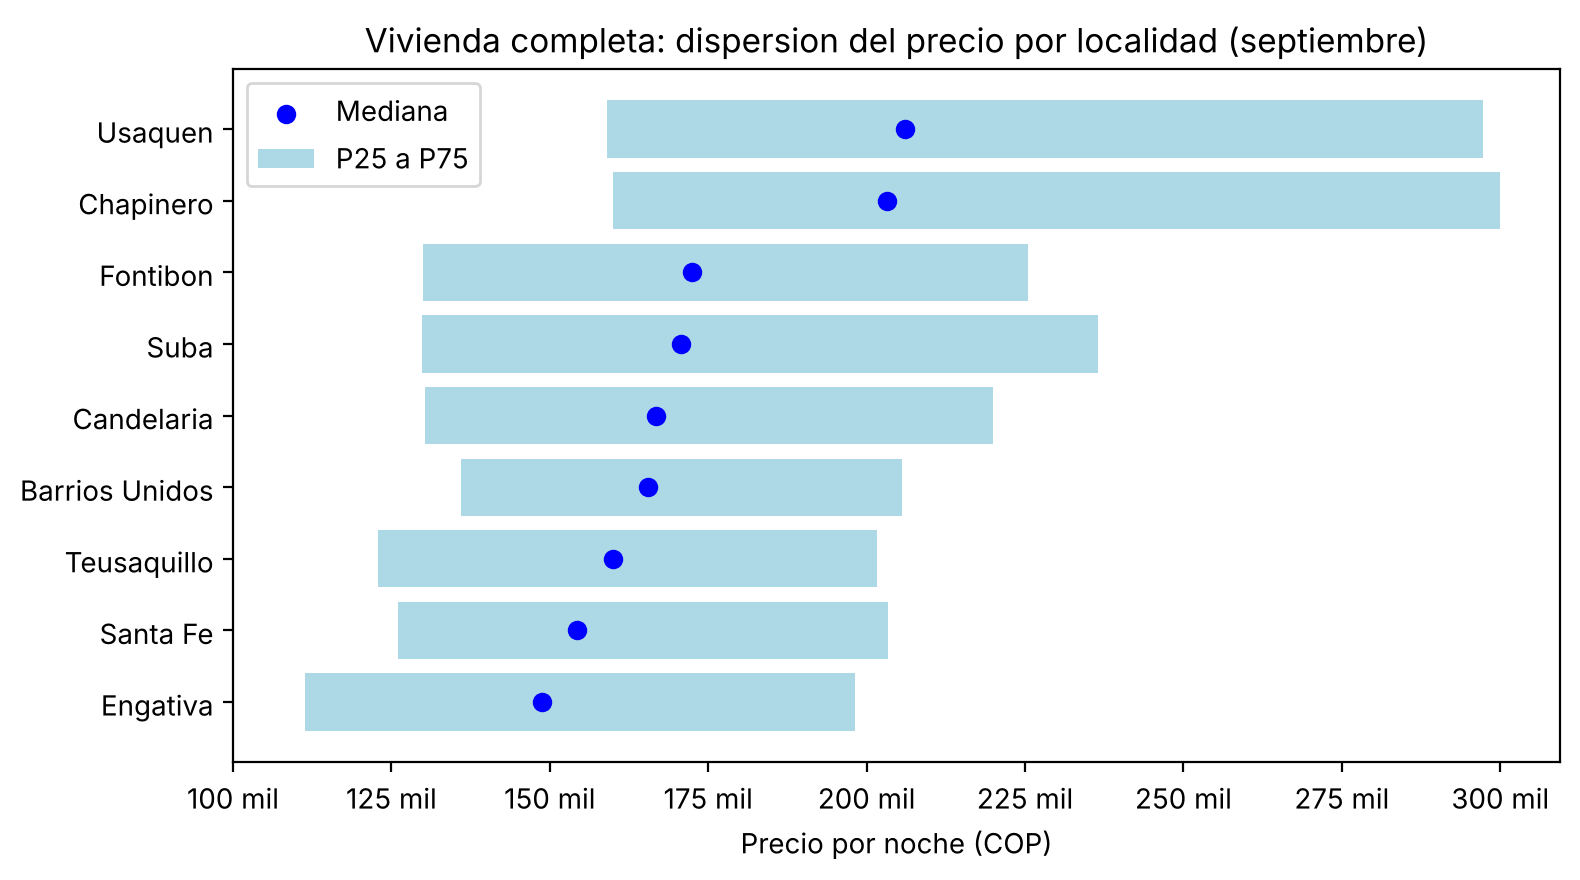

,count,25%,50%,75%,ric_sobre_mediana_%
neighbourhood_cleansed,,,,,
Engativa,683.00,"111,306.00","148,800.00","198,197.00",58.00
Santa Fe,"1,208.00","125,970.00","154,284.00","203,417.00",50.00
Teusaquillo,"1,682.00","122,869.00","160,000.00","201,648.00",49.00
Barrios Unidos,687.00,"135,975.00","165,454.00","205,574.00",42.00
Candelaria,378.00,"130,277.00","166,757.00","220,000.00",54.00
Suba,689.00,"129,846.00","170,660.00","236,479.00",62.00
Fontibon,575.00,"130,000.00","172,500.00","225,460.00",55.00
Chapinero,"4,227.00","160,000.00","203,264.00","300,000.00",69.00
Usaquen,"2,673.00","159,042.00","205,982.00","297,287.00",67.00


In [14]:
# Precio de viviendas completas por localidad: mediana y rango intercuartil
vc = jun.neighbourhood_cleansed.value_counts()
loc9 = vc[vc >= 500].index
e = x[(x.room_type == "Entire home/apt") & x.neighbourhood_cleansed.isin(loc9)]
t = e.groupby("neighbourhood_cleansed").p.describe()[["count", "25%", "50%", "75%"]].sort_values("50%")
t["ric_sobre_mediana_%"] = ((t["75%"] - t["25%"]) / t["50%"] * 100).round(0)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(t.index, t["75%"] - t["25%"], left=t["25%"], color="lightblue", label="P25 a P75")
ax.scatter(t["50%"], t.index, color="blue", zorder=3, label="Mediana")
ax.set_xlim(left=100000)
ax.set_xlabel("Precio por noche (COP)")
ax.set_title("Vivienda completa: dispersion del precio por localidad (septiembre)")
ax.xaxis.set_major_formatter(lambda v, _: f"{v/1000:,.0f} mil")
ax.legend()
plt.tight_layout(); plt.show()
t.round(0)

Oferta en las 9 localidades con al menos 500 anuncios: 94.4 %


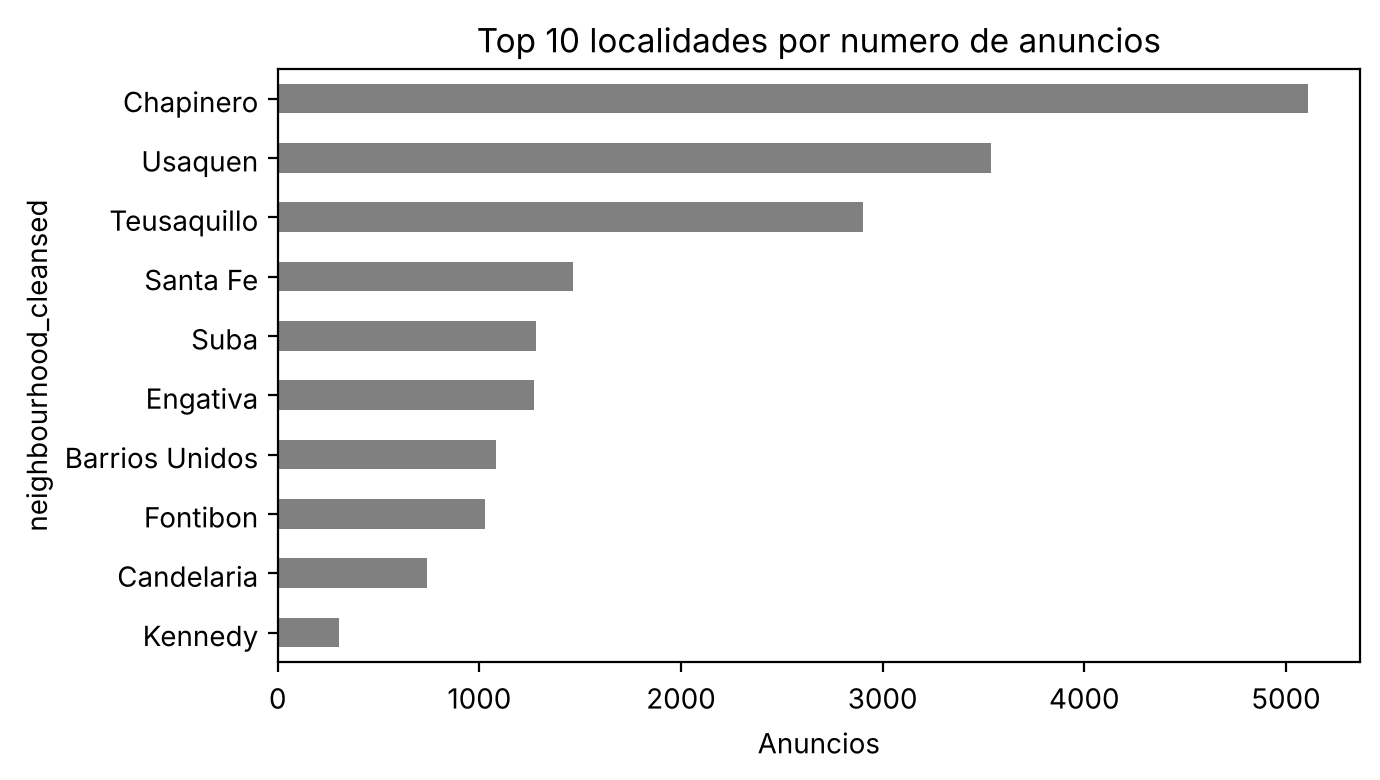

neighbourhood_cleansed
Ciudad Bolivar    44
Bosa              25
Tunjuelito        18
Usme              14
Sumapaz            3
Name: count, dtype: int64

In [15]:
# Concentracion de la oferta por localidad (septiembre)
oferta = sep.neighbourhood_cleansed.value_counts()
print(f"Oferta en las 9 localidades con al menos 500 anuncios: {sep.neighbourhood_cleansed.isin(loc9).mean() * 100:.1f} %")
oferta.head(10).sort_values().plot.barh(color="gray", figsize=(7, 4), title="Top 10 localidades por numero de anuncios")
plt.xlabel("Anuncios"); plt.tight_layout(); plt.show()
oferta.tail(5)

In [16]:
# Segmento objetivo: anfitriones con uno o dos anuncios
pequenos = sep.calculated_host_listings_count <= 2
print(f"Anuncios de anfitriones pequenos: {pequenos.sum():,} ({pequenos.mean() * 100:.1f} %)")
sm = x[x.calculated_host_listings_count <= 2]
celdas = sm.groupby(["neighbourhood_cleansed", "room_type"]).size()
pd.Series({"anuncios con precio valido": len(sm), "combinaciones localidad x tipo": len(celdas),
           "combinaciones con < 30 anuncios": int((celdas < 30).sum()),
           "anuncios en esas combinaciones": int(celdas[celdas < 30].sum())})

Anuncios de anfitriones pequenos: 8,071 (41.4 %)


anuncios con precio valido         7590
combinaciones localidad x tipo       50
combinaciones con < 30 anuncios      27
anuncios en esas combinaciones      222
dtype: int64

## 2. Dimensiones de valor de los datos

In [ ]:
# Edad de cada corte e integridad de la llave
corte = pd.Timestamp("2026-11-12")
pd.DataFrame({k: {
    "dias desde el raspado": (corte - pd.to_datetime(d.last_scraped).max()).days,
    "id duplicados": int(d.id.duplicated().sum()),
    "localidades": d.neighbourhood_cleansed.nunique(),
    "precio maximo (COP)": d.p.max(),
} for k, d in capturas.items()})

,junio,septiembre
dias desde el raspado,143.00,57.00
id duplicados,0.00,0.00
localidades,20.00,20.00
precio maximo (COP),"448,176,567.00","258,514,678.00"


## 3. Valor de los datos para el problema

In [18]:
# Disponibilidad de la variable objetivo y del segmento objetivo
pd.DataFrame({k: {
    "anuncios": len(d),
    "con precio (%)": round(d.p.notna().mean() * 100, 1),
    "anfitriones pequenos": int((d.calculated_host_listings_count <= 2).sum()),
} for k, d in capturas.items()})

,junio,septiembre
anuncios,"19,187.00","19,505.00"
con precio (%),99.00,96.40
anfitriones pequenos,"7,955.00","8,071.00"


## 4. Decisiones por provenir de diferentes fuentes

In [19]:
# Columnas vacias en una captura y no en la otra
vac_j = set(jun_raw.columns[jun_raw.isna().all()])
vac_s = set(sep_raw.columns[sep_raw.isna().all()])
print("Vacias solo en septiembre:", sorted(vac_s - vac_j))
print("Vacias solo en junio:", sorted(vac_j - vac_s))

Vacias solo en septiembre: ['bathrooms']
Vacias solo en junio: []


In [20]:
# Campos de la cotizacion presentes solo en una captura
def claves(d):
    q = d.price_quote_raw.dropna().map(lambda r: json.loads(r).get("quote") or {})
    return set().union(*q.map(set))

kj, ks = claves(jun), claves(sep)
print("Solo en septiembre:", sorted(ks - kj))
print("Solo en junio:", sorted(kj - ks))

Solo en septiembre: ['is_monthly_priced']
Solo en junio: []


In [21]:
# Registros heredados de la captura anterior sin precio
for k, d in capturas.items():
    her = d.source == "previous scrape"
    print(f"{k}: heredados {her.sum()}, sin precio {(her & d.p.isna()).sum()}")

junio: heredados 0, sin precio 0
septiembre: heredados 318, sin precio 193


## 5. Características de calidad de la base

### 5.1 Totalidad

In [22]:
# Celdas vacias y columnas sin ningun dato
for k, d in {"junio": jun_raw, "septiembre": sep_raw}.items():
    print(f"{k}: celdas vacias {d.isna().mean().mean() * 100:.1f} %, columnas 100 % vacias {int(d.isna().all().sum())}")
print("Vacias en ambas:", sorted(vac_j & vac_s))

junio: celdas vacias 18.2 %, columnas 100 % vacias 13
septiembre: celdas vacias 20.2 %, columnas 100 % vacias 14
Vacias en ambas: ['calendar_updated', 'host_acceptance_rate', 'host_neighbourhood', 'host_response_rate', 'host_response_time', 'host_since', 'host_thumbnail_url', 'host_total_listings_count', 'host_verifications', 'instant_bookable', 'neighborhood_overview', 'neighbourhood', 'neighbourhood_group_cleansed']


In [23]:
# Faltantes de las variables de interes
cols = ["price", "neighbourhood_cleansed", "room_type", "property_type", "accommodates", "minimum_nights",
        "amenities", "latitude", "longitude", "beds", "bathrooms_text", "bathrooms", "bedrooms",
        "review_scores_rating", "first_review", "last_review", "license", "host_since", "instant_bookable",
        "host_total_listings_count"]
pd.DataFrame({"junio_%": jun_raw[cols].isna().mean() * 100,
              "septiembre_%": sep_raw[cols].isna().mean() * 100}).round(1)

,junio_%,septiembre_%
price,1.00,3.60
neighbourhood_cleansed,0.00,0.00
room_type,0.00,0.00
property_type,0.00,0.00
accommodates,0.00,0.00
minimum_nights,0.00,0.00
amenities,0.00,0.00
latitude,0.00,0.00
longitude,0.00,0.00
beds,1.50,1.20


In [ ]:
# Reseñas faltantes corresponden a anuncios sin reseñas
for k, d in capturas.items():
    coincide = (d.review_scores_rating.isna() == (d.number_of_reviews == 0)).mean()
    print(f"{k}: coincidencia {coincide * 100:.1f} %")

junio: coincidencia 100.0 %
septiembre: coincidencia 100.0 %


### 5.2 Consistencia

In [25]:
# Estancias de 28 noches o mas y su precio por noche
filas = {}
for k, d in capturas.items():
    m = d.groupby(d.minimum_nights >= 28).p.median()
    filas[k] = {"anuncios con >= 28 noches (%)": round((d.minimum_nights >= 28).mean() * 100, 1),
                "mediana < 28 noches": m[False], "mediana >= 28 noches": m[True],
                "diferencia (%)": round((1 - m[True] / m[False]) * 100, 1)}
pd.DataFrame(filas)

,junio,septiembre
anuncios con >= 28 noches (%),17.80,17.50
mediana < 28 noches,"171,176.58","170,000.00"
mediana >= 28 noches,"108,057.60","96,480.10"
diferencia (%),36.90,43.20


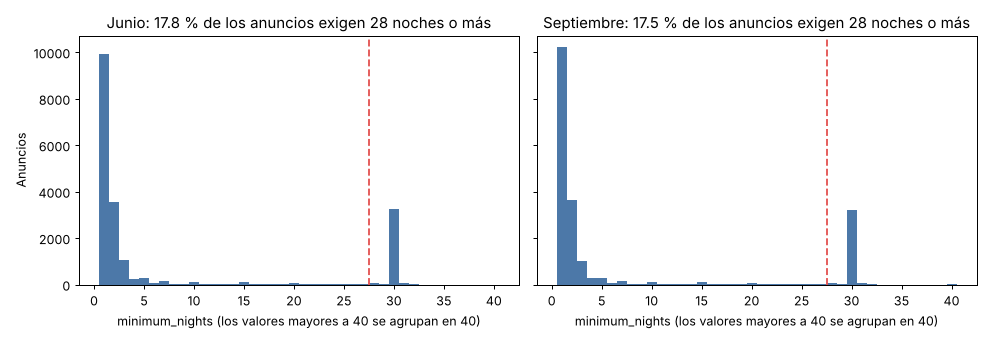

In [ ]:
# Distribucion de minimum_nights con corte en 28 noches (junio y septiembre)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, (k, d) in zip(ax, capturas.items()):
    mn = d.minimum_nights.clip(upper=40)
    a.hist(mn, bins=np.arange(0.5, 41.5, 1), color="#4C78A8")
    a.axvline(27.5, color="#E45756", ls="--")
    pct = (d.minimum_nights >= 28).mean() * 100
    a.set_title(f"{k.capitalize()}: {pct:.1f} % de los anuncios exigen 28 noches o más")
    a.set_xlabel("minimum_nights (los valores mayores a 40 se agrupan en 40)")
ax[0].set_ylabel("Anuncios")
plt.tight_layout(); plt.show()

In [26]:
# Mediana por noche segun noches cotizadas (septiembre)
tramos = pd.cut(sep.noches_cotizadas, [0, 1, 2, 6, 27, 31, 400],
                labels=["1", "2", "3-6", "7-27", "28-31", "32+"])
sep.groupby(tramos, observed=True).p.agg(["count", "median"])

,count,median
noches_cotizadas,,
1,9475,"170,498.16"
2,3795,"175,500.00"
3-6,1846,"156,445.84"
7-27,626,"156,161.60"
28-31,3017,"96,900.00"
32+,35,"124,412.53"


In [27]:
# Tipos de descuento en la cotizacion y descuento mediano sobre el subtotal
def descuentos(d):
    filas = []
    for i, raw in d.loc[d.p.notna(), "price_quote_raw"].dropna().items():
        q = json.loads(raw).get("quote") or {}
        sub = float(q["nightly_subtotal"]) if q.get("nightly_subtotal") else None
        for it in q.get("raw_price_line_items") or []:
            if it.get("item_type") == "discount_amount":
                pct = -float(it["amount"]) / sub * 100 if sub else np.nan
                filas.append({"id": i, "tipo": it["description"], "pct": pct})
    return pd.DataFrame(filas)

tabla = {}
for k, d in capturas.items():
    dd, n = descuentos(d), d.p.notna().sum()
    t = dd.groupby("tipo").agg(anuncios=("id", "nunique"), con_subtotal=("pct", "count"), mediana_pct=("pct", "median"))
    # Mediana solo con 30 o mas casos con subtotal
    t.loc[t.con_subtotal < 30, "mediana_pct"] = np.nan
    t["%_anuncios"] = t.anuncios / n * 100
    t.loc["Al menos un descuento"] = [dd.id.nunique(), np.nan, np.nan, dd.id.nunique() / n * 100]
    tabla[k] = t
desc = pd.concat(tabla, axis=1).fillna({("junio", "anuncios"): 0, ("junio", "%_anuncios"): 0})
desc.drop(columns=[("junio", "mediana_pct"), ("junio", "con_subtotal")]).round(1).sort_values(("septiembre", "anuncios"), ascending=False)

junio            septiembre                                    
                       anuncios %_anuncios   anuncios con_subtotal mediana_pct %_anuncios
tipo                                                                                     
Al menos un descuento  4,569.00      24.10   7,441.00          NaN         NaN      39.60
Last-minute discount       0.00       0.00   3,253.00     3,243.00        6.10      17.30
Monthly stay discount  1,902.00      10.00   1,732.00         1.00         NaN       9.20
Special offer          1,814.00       9.60   1,623.00     1,458.00       19.00       8.60
Weekly stay discount     507.00       2.70     443.00       351.00        9.30       2.40
Long stay discount       183.00       1.00     227.00       214.00        8.60       1.20
Early booking discount   170.00       0.90     178.00       176.00        7.20       0.90

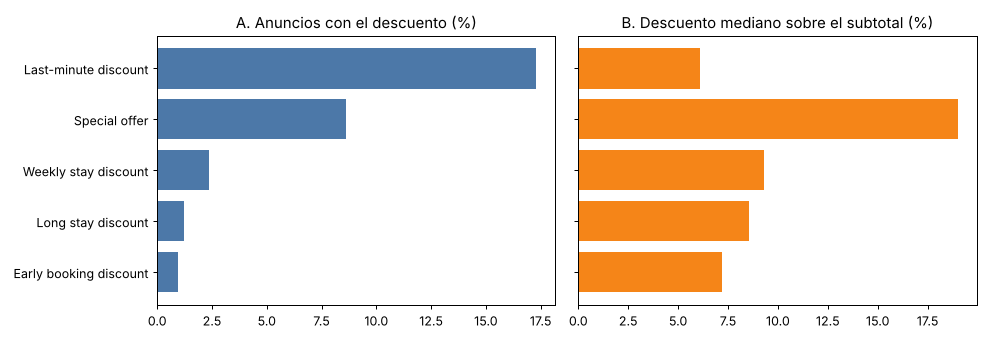

In [ ]:
# Descuentos por estancia larga: anuncios con cada tipo de descuento y descuento mediano (septiembre)
dd = descuentos(sep)
n = sep.p.notna().sum()
t = dd.groupby("tipo").agg(anuncios=("id", "nunique"), con_subtotal=("pct", "count"), mediana=("pct", "median"))
t = t[t.con_subtotal >= 30].sort_values("anuncios")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
ax[0].barh(t.index, t.anuncios / n * 100, color="#4C78A8")
ax[0].set_title("A. Anuncios con el descuento (%)")
ax[1].barh(t.index, t.mediana, color="#F58518")
ax[1].set_title("B. Descuento mediano sobre el subtotal (%)")
plt.tight_layout(); plt.show()

In [ ]:
# Cambio de definicion de bedrooms entre cortes 
m = jun[["id", "bedrooms"]].merge(sep[["id", "bedrooms", "property_type"]], on="id", suffixes=("_j", "_s"))
cambio = m.bedrooms_j.isna() & m.bedrooms_s.notna()
print(f"Sin dato en junio y con valor en septiembre: {cambio.sum():,}; de ellos con 0: {(cambio & (m.bedrooms_s == 0)).sum()}")
m.loc[cambio & (m.bedrooms_s == 0), "property_type"].value_counts().head(5)

Sin dato en junio y con valor en septiembre: 2,816; de ellos con 0: 471


property_type
Entire rental unit             196
Entire loft                     61
Private room in rental unit     43
Shared room in hotel            38
Private room in home            35
Name: count, dtype: int64

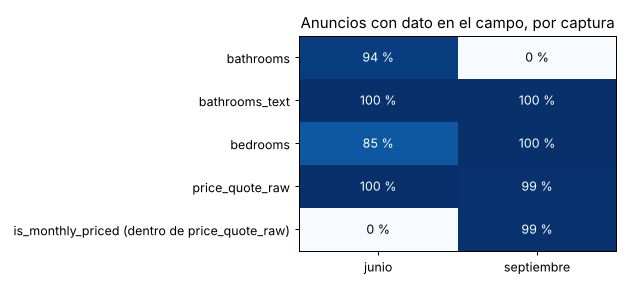

In [ ]:
# Esquema por captura: porcentaje de anuncios con dato en cada campo que cambia entre cortes
def con_dato(d):
    q = d.price_quote_raw.dropna().map(lambda r: json.loads(r).get("quote") or {})
    return {
        "bathrooms": d.bathrooms.notna().mean(),
        "bathrooms_text": d.bathrooms_text.notna().mean(),
        "bedrooms": d.bedrooms.notna().mean(),
        "price_quote_raw": d.price_quote_raw.notna().mean(),
        "is_monthly_priced (dentro de price_quote_raw)": q.map(lambda x: "is_monthly_priced" in x).sum() / len(d),
    }

esq = pd.DataFrame({k: con_dato(d) for k, d in capturas.items()}) * 100
fig, ax = plt.subplots(figsize=(7, 3.2))
im = ax.imshow(esq.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(2), esq.columns); ax.set_yticks(range(len(esq)), esq.index)
for i in range(len(esq)):
    for j in range(2):
        v = esq.values[i, j]
        ax.text(j, i, f"{v:.0f} %", ha="center", va="center", color="white" if v > 55 else "black")
ax.set_title("Anuncios con dato en el campo, por captura")
plt.tight_layout(); plt.show()

In [ ]:
# Dos conteos de anuncios por anfitrion y relaciones improbables (septiembre)
pd.Series({
    "host_listings_count != calculated": int((sep.host_listings_count != sep.calculated_host_listings_count).sum()),
    "% de anuncios": round((sep.host_listings_count != sep.calculated_host_listings_count).mean() * 100, 1),
    "camas > 2 x huespedes": int((sep.beds > 2 * sep.accommodates).sum()),
    "habitaciones > huespedes": int((sep.bedrooms > sep.accommodates).sum()),
    "maximum_nights = 2.147.483.647": int((sep.maximum_nights == 2147483647).sum()),
})

host_listings_count != calculated   6,524.00
% de anuncios                          33.40
camas > 2 x huespedes                 131.00
habitaciones > huespedes              211.00
maximum_nights = 2.147.483.647          4.00
dtype: float64

In [30]:
# Reglas de consistencia que si se cumplen
pt = sep.property_type.str.lower()
bt = sep.bathrooms_text.fillna("")
bt_num = jun.bathrooms_text.str.extract(r"([\d.]+)")[0].astype(float)
ambos = bt_num.notna() & jun.bathrooms.notna()
pd.Series({
    "id duplicados (sep)": int(sep.id.duplicated().sum()),
    "filas identicas salvo id (jun)": int(jun_raw.drop(columns=["id", "listing_url"]).duplicated().sum()),
    "tipo de propiedad contradice tipo de alojamiento": int(((pt.str.startswith("private room") & (sep.room_type != "Private room")) |
                                                              (pt.str.startswith("entire") & (sep.room_type != "Entire home/apt"))).sum()),
    "vivienda completa con bano compartido": int((bt.str.contains("shared", case=False) & (sep.room_type == "Entire home/apt")).sum()),
    "calificaciones fuera de [0, 5]": int(((sep.review_scores_rating < 0) | (sep.review_scores_rating > 5)).sum()),
    "primera resena posterior a la ultima": int((pd.to_datetime(sep.first_review) > pd.to_datetime(sep.last_review)).sum()),
    "banos texto == numerico (jun)": f"{int(((bt_num - jun.bathrooms).abs() < 0.01)[ambos].sum())} de {int(ambos.sum())}",
    "latitud min / max": f"{sep.latitude.min():.3f} / {sep.latitude.max():.3f}",
    "longitud min / max": f"{sep.longitude.min():.3f} / {sep.longitude.max():.3f}",
})

id duplicados (sep)                                                 0
filas identicas salvo id (jun)                                      1
tipo de propiedad contradice tipo de alojamiento                    0
vivienda completa con bano compartido                               0
calificaciones fuera de [0, 5]                                      0
primera resena posterior a la ultima                                0
banos texto == numerico (jun)                          18022 de 18022
latitud min / max                                       4.028 / 4.822
longitud min / max                                  -74.315 / -74.004
dtype: object

### 5.3 Claridad

In [31]:
# Estadisticos del precio y valores extremos (septiembre)
s = sep[sep.p.notna()]
mediana_celda = s.groupby(["neighbourhood_cleansed", "room_type"]).p.transform("median")
pd.Series({"media": s.p.mean(), "mediana": s.p.median(), "maximo": s.p.max(),
           "anuncios > 2 millones": (s.p > 2e6).sum(),
           "anuncios > 5 veces la mediana de su localidad y tipo": (s.p > 5 * mediana_celda).sum(),
           "anuncios por encima del P99 de junio": (s.p > p99).sum()}).round(0)

media                                                      292,878.00
mediana                                                    160,772.00
maximo                                                 258,514,678.00
anuncios > 2 millones                                           95.00
anuncios > 5 veces la mediana de su localidad y tipo           351.00
anuncios por encima del P99 de junio                           191.00
dtype: float64

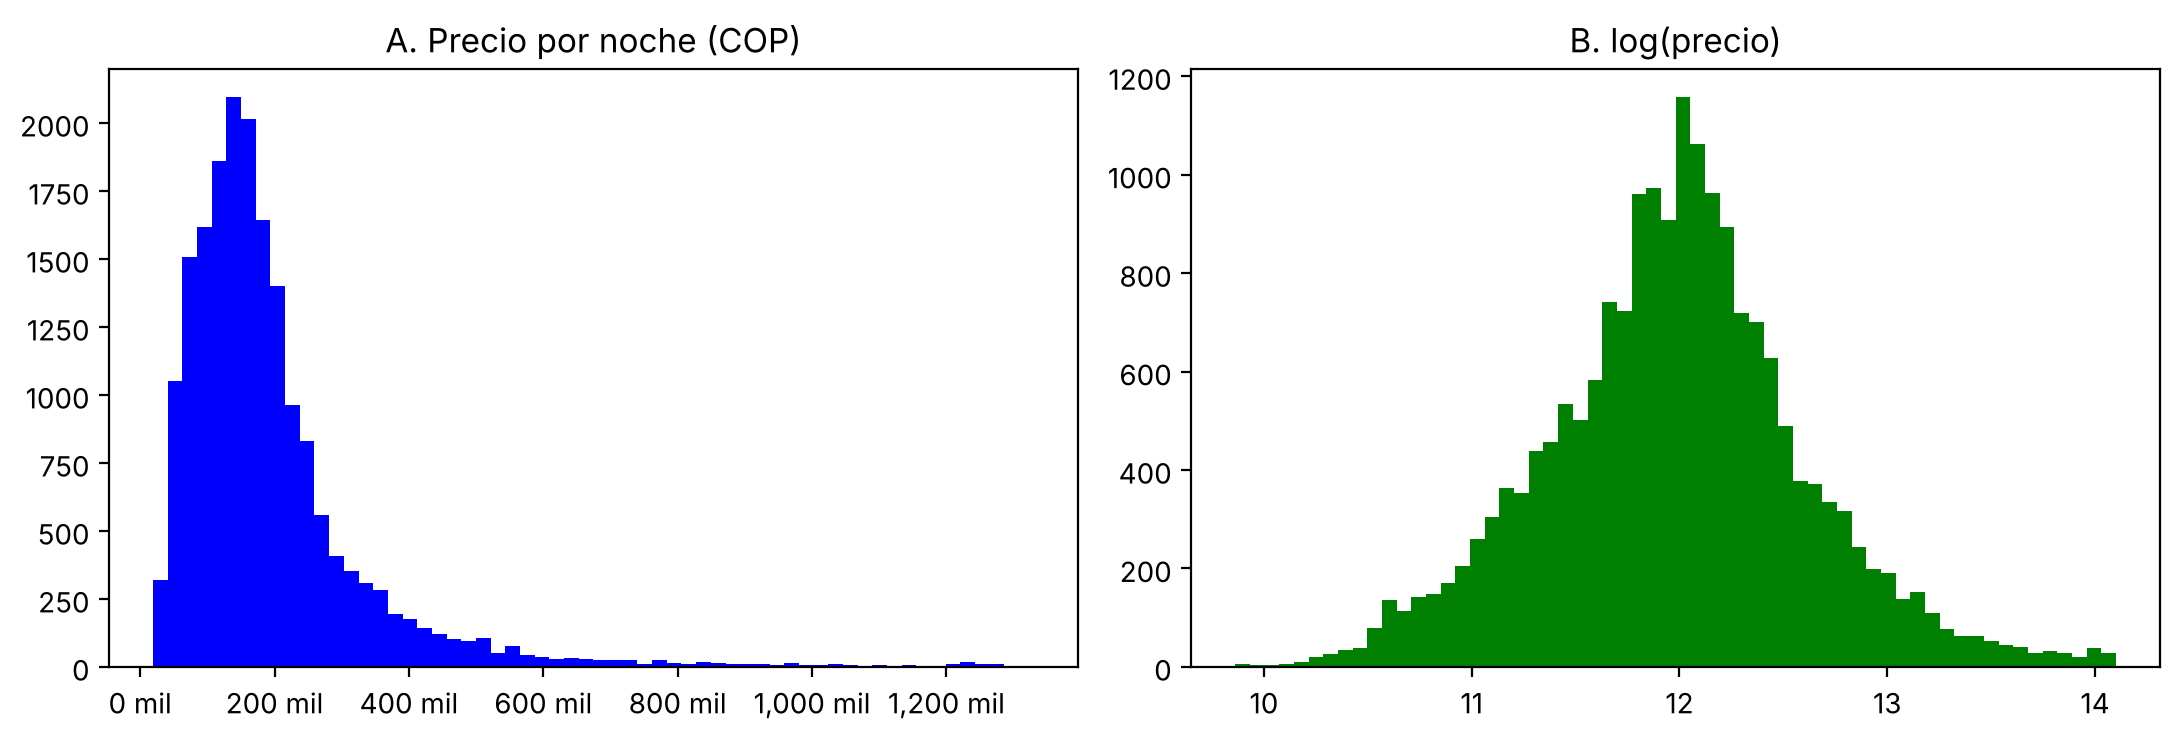

In [ ]:
# Distribucion del precio en escala original y logaritmica (junio)
lj = jun[(jun.p > 0) & (jun.p <= p99)].p
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(lj, bins=60, color="blue")
ax[0].set_title("A. Precio por noche (COP)")
ax[0].xaxis.set_major_formatter(lambda v, _: f"{v/1000:,.0f} mil")
ax[1].hist(np.log(lj), bins=60, color="green")
ax[1].set_title("B. log(precio)")
plt.tight_layout(); plt.show()

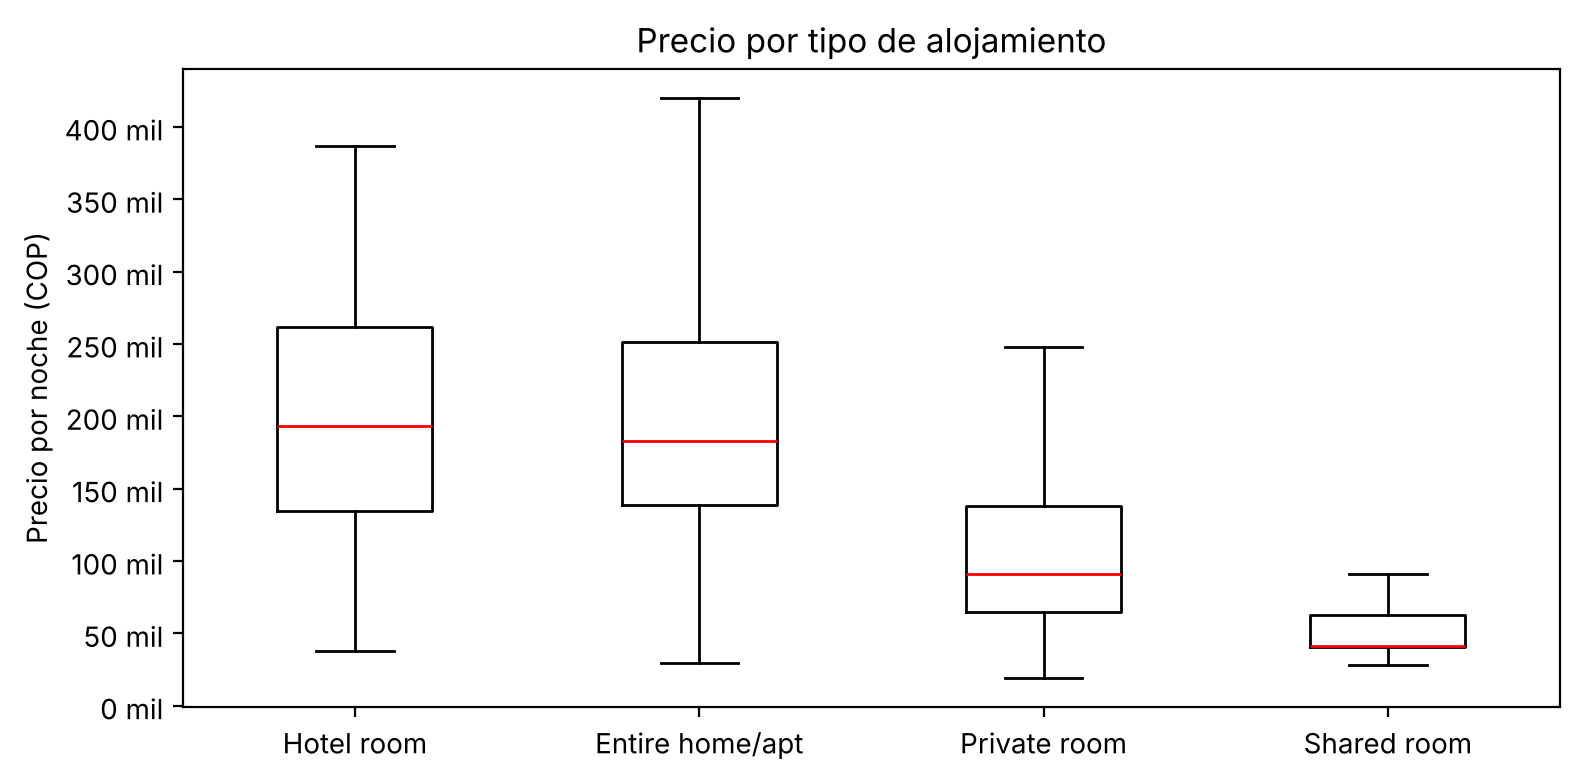

,count,median
room_type,,
Entire home/apt,13577,"182,588.32"
Hotel room,33,"193,048.00"
Private room,5075,"91,295.00"
Shared room,117,"41,453.00"


In [ ]:
# Precio por noche segun tipo de alojamiento (junio)
lj = jun[(jun.p > 0) & (jun.p <= p99)]
orden = lj.groupby("room_type").p.median().sort_values(ascending=False).index
plt.figure(figsize=(8, 4))
plt.boxplot([lj.loc[lj.room_type == t, "p"] for t in orden], tick_labels=orden, showfliers=False,
            medianprops={"color": "red"})
plt.ylabel("Precio por noche (COP)")
plt.title("Precio por tipo de alojamiento")
plt.gca().yaxis.set_major_formatter(lambda v, _: f"{v/1000:,.0f} mil")
plt.tight_layout(); plt.show()
lj.groupby("room_type").p.agg(["count", "median"])

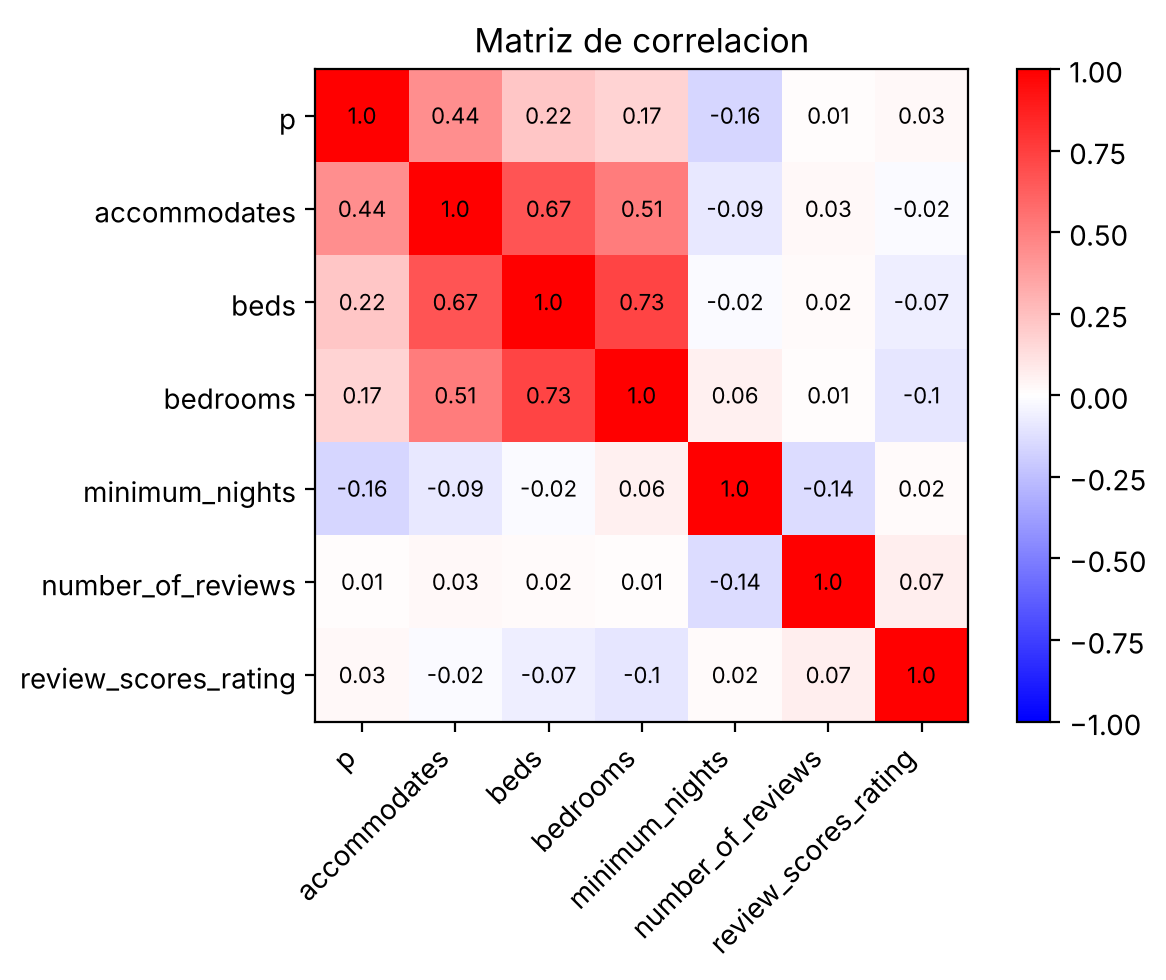

In [ ]:
# Correlacion de Pearson entre variables numericas y el precio (junio)
num = ["p", "accommodates", "beds", "bedrooms", "minimum_nights", "number_of_reviews", "review_scores_rating"]
corr = lj[num].corr().round(2)
fig, ax = plt.subplots(figsize=(6.5, 5))
im = ax.imshow(corr, cmap="bwr", vmin=-1, vmax=1)
ax.set_xticks(range(len(num)), num, rotation=45, ha="right"); ax.set_yticks(range(len(num)), num)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, corr.iloc[i, j], ha="center", va="center", fontsize=8)
fig.colorbar(im); ax.set_title("Matriz de correlacion")
plt.tight_layout(); plt.show()

In [35]:
# Categorias con pocos registros
vc_pt = sep.property_type.value_counts()
print(f"Tipos de propiedad: {len(vc_pt)}, con menos de 50 anuncios: {(vc_pt < 50).sum()}")
sep.room_type.value_counts()

Tipos de propiedad: 71, con menos de 50 anuncios: 53


room_type
Entire home/apt    14123
Private room        5234
Shared room          119
Hotel room            29
Name: count, dtype: int64

### 5.4 Formato

In [36]:
# Ejemplos del formato recibido
sep[["price", "bathrooms_text", "neighbourhood_cleansed", "host_is_superhost", "last_scraped", "license"]].head(5)

,price,bathrooms_text,neighbourhood_cleansed,host_is_superhost,last_scraped,license
0,"$274,830.78",2.5 baths,Chapinero,t,2026-09-16,"112,727.00"
1,"$71,692.74",0 shared baths,Chapinero,f,2026-09-16,NaN
2,"$137,358.40",1 bath,Chapinero,f,2026-09-16,"183,725.00"
3,"$173,779.33",2 baths,Chapinero,f,2026-09-16,"142,019.00"
4,"$67,154.71",1 private bath,Chapinero,f,2026-09-16,NaN


In [ ]:
# Amenities: textos distintos
am = pd.Series([a for r in sep.amenities for a in json.loads(r)])
print(f"Textos distintos: {am.nunique():,}")
wifi = am[am.str.contains("wifi", case=False)].unique()
print(f"Variantes con 'wifi': {len(wifi)}; ejemplos: {list(wifi[:4])}")

Textos distintos: 3,707
Variantes con 'wifi': 399; ejemplos: ['Wifi', 'Fast wifi – 213 Mbps', 'Pocket wifi', 'Fast wifi – 216 Mbps']


In [38]:
# Localidades con y sin tilde
nombres = pd.Series(sep.neighbourhood_cleansed.unique())
print("Con caracteres no ASCII:", list(nombres[nombres.str.contains(r"[^\x00-\x7F]")]))
print(sorted(nombres)[:8])

Con caracteres no ASCII: ['Antonio Nariño']
['Antonio Nariño', 'Barrios Unidos', 'Bosa', 'Candelaria', 'Chapinero', 'Ciudad Bolivar', 'Engativa', 'Fontibon']


In [39]:
# Licencia leida como numero decimal y repetida entre anuncios
print("Tipo de dato:", sep.license.dtype, "| ejemplo:", sep.license.dropna().iloc[0])
print("Numeros repetidos en mas de un anuncio:", int((sep.license.value_counts() > 1).sum()))

Tipo de dato: float64 | ejemplo: 112727.0
Numeros repetidos en mas de un anuncio: 1969


## 6. Concordancia con el problema de negocio

In [40]:
# Base de modelado: precio valido, hasta P99 y 9 localidades con al menos 500 anuncios
def filtro(d):
    return d[d.p.notna() & (d.p <= p99) & d.neighbourhood_cleansed.isin(loc9)].copy()

fj, fs = filtro(jun), filtro(sep)
nuevos = ~fs.id.isin(jun.id)
pasos = pd.DataFrame({
    "junio": [len(jun), jun.p.isna().sum(), (jun.p > p99).sum(), (~jun.neighbourhood_cleansed.isin(loc9)).sum(), len(fj), np.nan],
    "septiembre": [len(sep), sep.p.isna().sum(), (sep.p > p99).sum(), (~sep.neighbourhood_cleansed.isin(loc9)).sum(), len(fs), nuevos.sum()],
}, index=["anuncios en el archivo", "sin precio", "precio > P99 de junio", "fuera de las 9 localidades",
          "base de modelado", "nuevos respecto a junio"])
print(f"Nuevos en septiembre: {nuevos.mean() * 100:.1f} %")
pasos

Nuevos en septiembre: 9.3 %


,junio,septiembre
anuncios en el archivo,"19,187.00",19505
sin precio,195.00,711
precio > P99 de junio,190.00,191
fuera de las 9 localidades,"1,086.00",1094
base de modelado,"17,749.00",17561
nuevos respecto a junio,NaN,1632


In [41]:
# Indicador de estancia mensual (28 noches o mas)
for d in (fj, fs):
    d["estancia_mensual"] = (d.minimum_nights >= 28).astype(int)
pd.DataFrame({"junio": fj.estancia_mensual.value_counts(), "septiembre": fs.estancia_mensual.value_counts()})

,junio,septiembre
estancia_mensual,,
0,14708,14829
1,3041,2732


In [42]:
# Linea base: mediana de junio por localidad y tipo aplicada a septiembre
ref = fj.groupby(["neighbourhood_cleansed", "room_type"]).p.median().rename("ref")
ev = fs.join(ref, on=["neighbourhood_cleansed", "room_type"]).dropna(subset=["ref"])

def metricas(d):
    return {"MdAPE (%)": (abs(d.ref - d.p) / d.p).median() * 100,
            "MAE (COP)": (d.ref - d.p).abs().mean(),
            "RMSE log": np.sqrt(((np.log(d.ref) - np.log(d.p)) ** 2).mean())}

pd.DataFrame({"septiembre completo": metricas(ev),
              "solo anuncios nuevos": metricas(ev[~ev.id.isin(jun.id)])}).map(lambda v: f"{v:,.4f}")

,septiembre completo,solo anuncios nuevos
MdAPE (%),29.5257,29.0425
MAE (COP),"76,895.1489","75,937.0404"
RMSE log,0.5168,0.4929


In [43]:
# Variables del formulario completas en la base de modelado
form = ["neighbourhood_cleansed", "room_type", "property_type", "accommodates", "minimum_nights", "amenities", "bathrooms_text", "beds"]
pd.DataFrame({"junio_%": fj[form].isna().mean() * 100, "septiembre_%": fs[form].isna().mean() * 100}).round(2)

,junio_%,septiembre_%
neighbourhood_cleansed,0.00,0.00
room_type,0.00,0.00
property_type,0.00,0.00
accommodates,0.00,0.00
minimum_nights,0.02,0.04
amenities,0.00,0.00
bathrooms_text,0.16,0.16
beds,1.53,1.19


In [44]:
# Campos personales, columnas vacias y variables con fuga que se excluyen
personales = ["host_name", "host_url", "host_profile_url", "host_about", "host_location", "host_picture_url",
              "picture_url", "listing_url", "name", "description"]
fuga = [c for c in sep_raw.columns if c.startswith("review_scores_")] + ["number_of_reviews", "first_review", "last_review",
        "reviews_per_month", "estimated_occupancy_l365d", "estimated_revenue_l365d"]
excluir = set(personales) | vac_j | vac_s | set(fuga)
print(f"Columnas excluidas: {len(excluir)} | columnas restantes: {sep_raw.shape[1] - len(excluir)}")

Columnas excluidas: 37 | columnas restantes: 53
